Shape merged: (103380, 4)
   ID  cat  stacking  user_aggreg
0   0    1         1            0
1   2    1         1            1
2   4    0         0            1
3   8    1         1            1
4   9    0         0            0


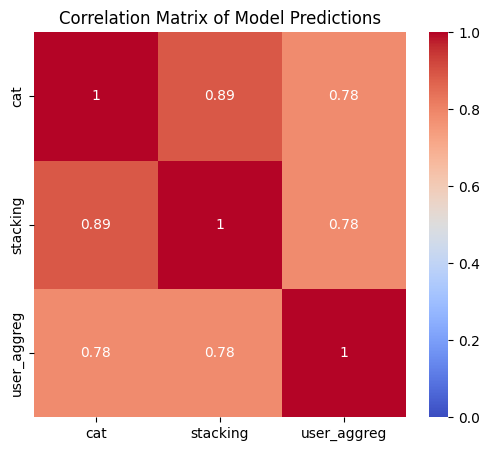


===== CORRELATION MATRIX =====
                  cat  stacking  user_aggreg
cat          1.000000  0.888030     0.783193
stacking     0.888030  1.000000     0.782706
user_aggreg  0.783193  0.782706     1.000000

===== AGREEMENT RATES =====
cat vs stacking     : 0.9447765525246663
cat vs user_aggreg  : 0.8931514799767847
stacking vs user_aggreg : 0.892851615399497


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


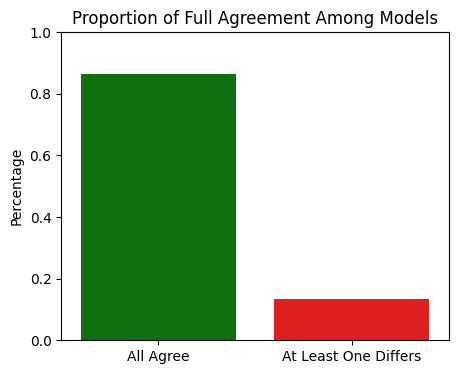


% of samples where ALL models agree: 0.8653898239504739


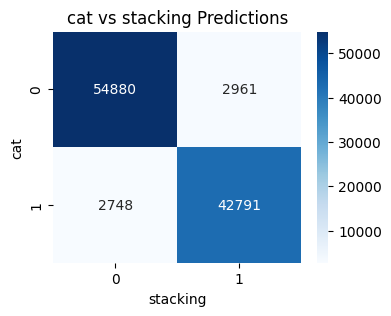


cat vs stacking:
 stacking      0      1
cat                   
0         54880   2961
1          2748  42791


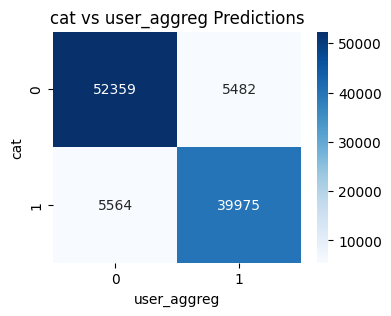


cat vs user_aggreg:
 user_aggreg      0      1
cat                      
0            52359   5482
1             5564  39975


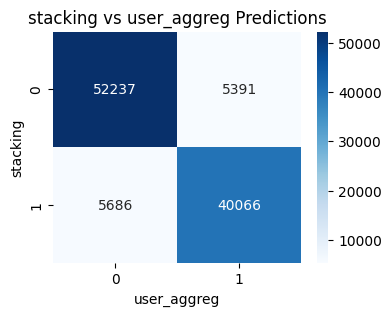


stacking vs user_aggreg:
 user_aggreg      0      1
stacking                 
0            52237   5391
1             5686  40066


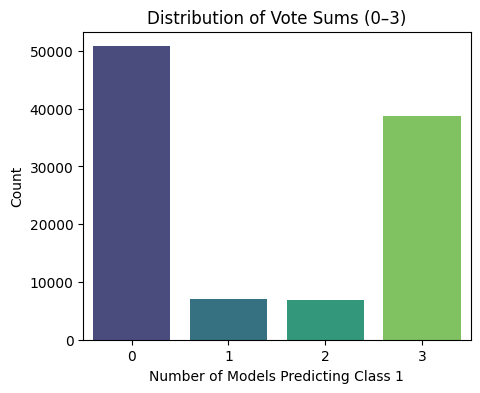

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------
# Load submissions
# ---------------------------
cat = pd.read_csv("/kaggle/input/each-best-models/catboost_submission_final.csv")
ultimate = pd.read_csv("/kaggle/input/each-best-models/submission_ultimate_ensemble.csv")
xgb = pd.read_csv("/kaggle/input/each-best-models/submission_user_level_xgb.csv")

# ---------------------------
# Fix column names
# ---------------------------
if "Prediction" in cat.columns:
    cat = cat.rename(columns={"Prediction": "cat"})

if "Prediction" in ultimate.columns:
    ultimate = ultimate.rename(columns={"Prediction": "stacking"})  # <-- rename

xgb = xgb.rename(columns={"label": "user_aggreg"})  # <-- rename

# ---------------------------
# Merge on ID
# ---------------------------
df = (
    cat[["ID", "cat"]]
    .merge(ultimate[["ID", "stacking"]], on="ID")
    .merge(xgb[["ID", "user_aggreg"]], on="ID")
)

print("Shape merged:", df.shape)
print(df.head())

# ======================================================
# 1) Correlation Matrix
# ======================================================
corr_matrix = df[["cat", "stacking", "user_aggreg"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Correlation Matrix of Model Predictions")
plt.show()

print("\n===== CORRELATION MATRIX =====")
print(corr_matrix)

# ======================================================
# 2) AGREEMENT RATES
# ======================================================
def agreement(a, b):
    return (a == b).mean()

print("\n===== AGREEMENT RATES =====")
print("cat vs stacking     :", agreement(df["cat"], df["stacking"]))
print("cat vs user_aggreg  :", agreement(df["cat"], df["user_aggreg"]))
print("stacking vs user_aggreg :", agreement(df["stacking"], df["user_aggreg"]))

# ======================================================
# 3) FULL AGREEMENT BARPLOT
# ======================================================
df["all_agree"] = (
    (df["cat"] == df["stacking"]) & 
    (df["cat"] == df["user_aggreg"])
)

plt.figure(figsize=(5, 4))
sns.barplot(
    x=["All Agree", "At Least One Differs"],
    y=[df["all_agree"].mean(), 1 - df["all_agree"].mean()],
    palette=["green", "red"],
)
plt.title("Proportion of Full Agreement Among Models")
plt.ylabel("Percentage")
plt.ylim(0, 1)
plt.show()

print("\n% of samples where ALL models agree:", df["all_agree"].mean())

# ======================================================
# 4) Pairwise contingency heatmaps
# ======================================================
def show_pairwise_heatmap(a, b, name1, name2):
    tab = pd.crosstab(a, b)
    plt.figure(figsize=(4, 3))
    sns.heatmap(tab, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name1} vs {name2} Predictions")
    plt.xlabel(name2)
    plt.ylabel(name1)
    plt.show()
    print(f"\n{name1} vs {name2}:\n", tab)

show_pairwise_heatmap(df["cat"], df["stacking"], "cat", "stacking")
show_pairwise_heatmap(df["cat"], df["user_aggreg"], "cat", "user_aggreg")
show_pairwise_heatmap(df["stacking"], df["user_aggreg"], "stacking", "user_aggreg")

# ======================================================
# 5) Vote distribution visualization
# ======================================================
df["vote_sum"] = df["cat"] + df["stacking"] + df["user_aggreg"]

plt.figure(figsize=(5,4))
sns.countplot(x=df["vote_sum"], palette="viridis")
plt.title("Distribution of Vote Sums (0–3)")
plt.xlabel("Number of Models Predicting Class 1")
plt.ylabel("Count")
plt.show()


In [3]:
import pandas as pd
import numpy as np

# ============================================================
# 1) LOAD THE THREE SUBMISSIONS
# ============================================================

path_cat    = "/kaggle/input/each-best-models/catboost_submission_final.csv"
path_ens    = "/kaggle/input/each-best-models/submission_ultimate_ensemble.csv"
path_user   = "/kaggle/input/each-best-models/submission_user_level_xgb.csv"

df_cat  = pd.read_csv(path_cat)
df_ens  = pd.read_csv(path_ens)
df_user = pd.read_csv(path_user)

print("Loaded shapes:", df_cat.shape, df_ens.shape, df_user.shape)


# ============================================================
# 2) VERIFY SAME ORDER / SAME KEYS
# ============================================================

if not (df_cat["ID"].equals(df_ens["ID"]) and df_cat["ID"].equals(df_user["ID"])):
    print("⚠️ WARNING: IDs are not aligned. Merging by ID...")

    df = df_cat.merge(df_ens, on="ID", how="inner", suffixes=("_cat", "_ens"))
    df = df.merge(df_user, on="ID", how="inner")
    df = df.rename(columns={"label": "label_user"})
else:
    print("IDs aligned perfectly ✓")
    df = pd.DataFrame({
        "ID": df_cat["ID"],
        "label_cat": df_cat["Prediction"],
        "label_ens": df_ens["Prediction"],
        "label_user": df_user["label"],
    })


# ============================================================
# 3) HARD VOTE (MAJORITY VOTE)
# ============================================================

labels = df[["label_cat", "label_ens", "label_user"]].values

# Majority vote: sum > 1  → class 1, otherwise 0
df["label"] = (labels.sum(axis=1) >= 2).astype(int)

print(df["label"].value_counts())


# ============================================================
# 4) SAVE FINAL SUBMISSION
# ============================================================

submission = df[["ID", "label"]]
submission_path = "/kaggle/working/submission_hardvote.csv"
submission.to_csv(submission_path, index=False)

print("\n🎉 Hard-vote submission saved to:", submission_path)
print(submission.head())


Loaded shapes: (103380, 2) (103380, 2) (103380, 2)
IDs aligned perfectly ✓
label
0    57888
1    45492
Name: count, dtype: int64

🎉 Hard-vote submission saved to: /kaggle/working/submission_hardvote.csv
   ID  label
0   0      1
1   2      1
2   4      0
3   8      1
4   9      0
